<center><h1>Sun_Yizhi_HW5</h1></center>
<br>
<br>

Name: Yizhi Sun
<br>
Github Username: yizhisun515
<br>
USC ID: 6129500198

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

from xgboost import XGBRegressor

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

### (a) Obtain Data

Get the Accute Inamations Data Set

In [2]:
data_path = Path("../data/diagnosis.data")

column_names = [
    "Temperature",
    "Nausea",
    "Lumbar_pain",
    "Urine_pushing",
    "Micturition_pains",
    "Burning_urethra",
    "Bladder_inflammation",
    "Renal_pelvis_nephritis"
]

df_diagnosis = pd.read_csv(
    data_path,
    header=None,
    names=column_names,
    sep=r"\s+",
    decimal=",",
    encoding="utf-16"
)

print("Dataset shape:", df_diagnosis.shape)
display(df_diagnosis.head())

print("\nMissing values:")
print(df_diagnosis.isnull().sum())

Dataset shape: (120, 8)


,Temperature,Nausea,Lumbar_pain,Urine_pushing,Micturition_pains,Burning_urethra,Bladder_inflammation,Renal_pelvis_nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no



Missing values:
Temperature               0
Nausea                    0
Lumbar_pain               0
Urine_pushing             0
Micturition_pains         0
Burning_urethra           0
Bladder_inflammation      0
Renal_pelvis_nephritis    0
dtype: int64


### (b) Build a decision tree

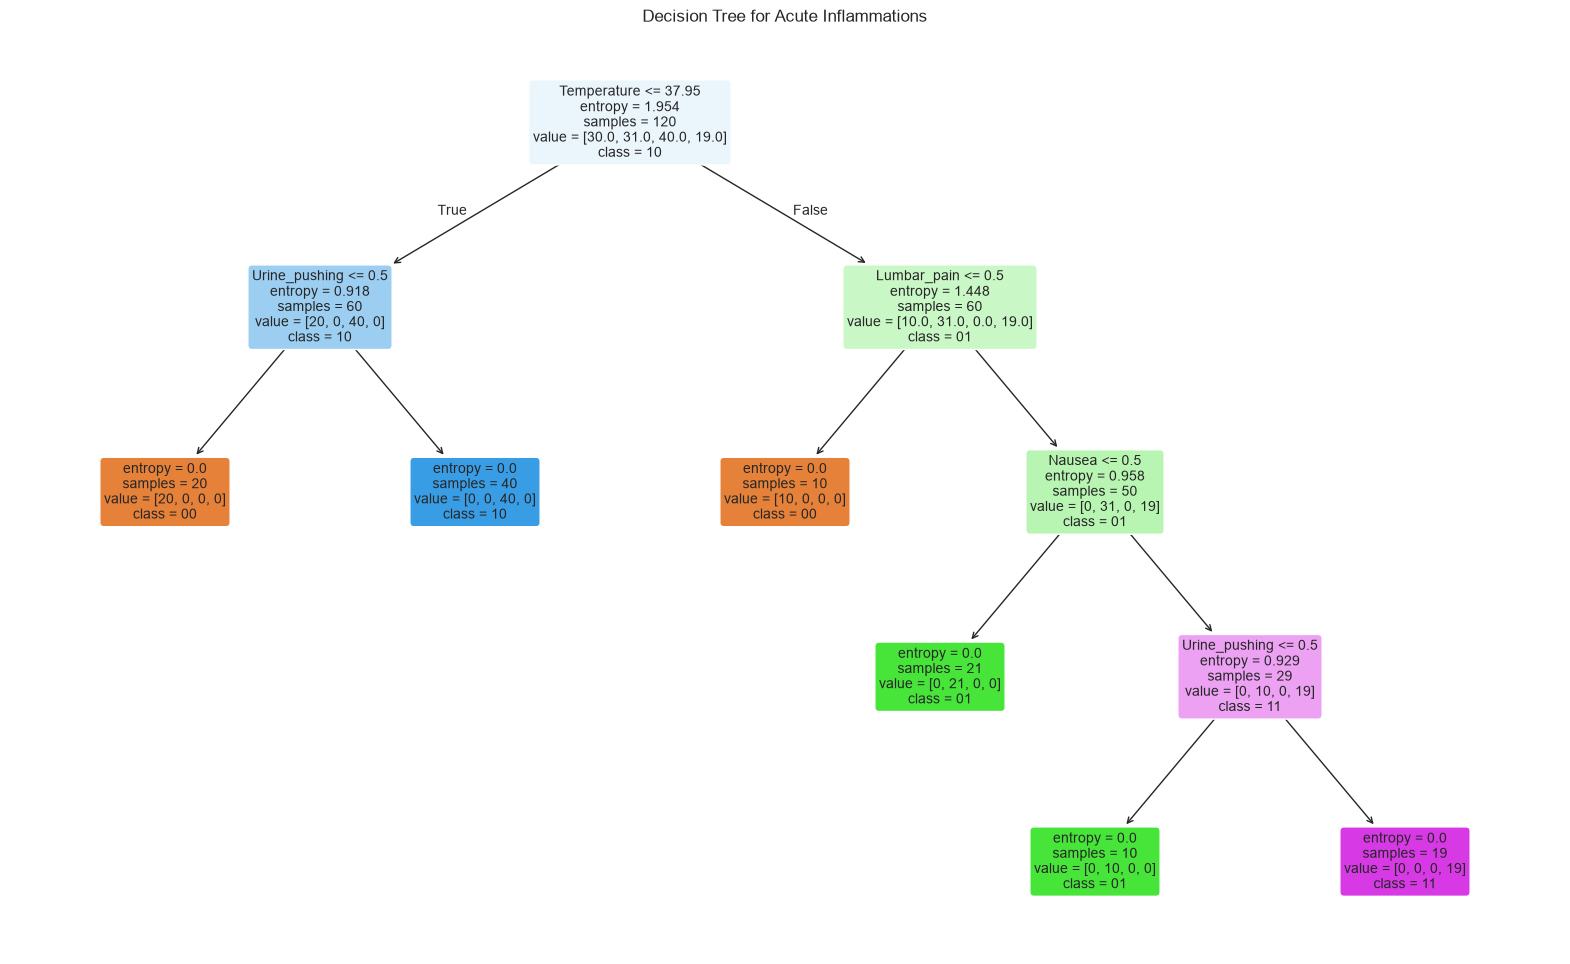

Tree depth: 4
Number of leaves: 6
Training accuracy: 1.0
Class labels: ['00' '01' '10' '11']


In [3]:
# Separate predictors and outcomes
X = df_diagnosis.iloc[:, :6].copy()
y = df_diagnosis.iloc[:, 6:].copy()

# Encode categorical predictors
binary_cols = X.columns.drop("Temperature")
X[binary_cols] = X[binary_cols].replace({"yes": 1, "no": 0}).astype(int)

# Label Powerset: combine the two disease labels
y_binary = y.replace({"yes": 1, "no": 0}).astype(int)
y_combined = (
    y_binary.iloc[:, 0].astype(str) +
    y_binary.iloc[:, 1].astype(str)
)

# Fit decision tree on the entire dataset
dt = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)
dt.fit(X, y_combined)

# Plot the decision tree
plt.figure(figsize=(20, 12))
plot_tree(
    dt,
    feature_names=X.columns,
    class_names=dt.classes_,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree for Acute Inflammations")
plt.show()

print("Tree depth:", dt.get_depth())
print("Number of leaves:", dt.get_n_leaves())
print("Training accuracy:", dt.score(X, y_combined))
print("Class labels:", dt.classes_)

### (c) Convert the decision rules

In [4]:
from sklearn.tree import _tree

def extract_rules(model, feature_names):
    tree_ = model.tree_
    rules = []

    def traverse(node, conditions):
        if tree_.feature[node] != _tree.TREE_UNDEFINED:
            feature = feature_names[tree_.feature[node]]
            threshold = tree_.threshold[node]

            traverse(
                tree_.children_left[node],
                conditions + [f"{feature} <= {threshold:.2f}"]
            )

            traverse(
                tree_.children_right[node],
                conditions + [f"{feature} > {threshold:.2f}"]
            )
        else:
            class_index = np.argmax(tree_.value[node][0])
            prediction = model.classes_[class_index]
            rule = " AND ".join(conditions)
            rules.append((rule, prediction))

    traverse(0, [])
    return rules


rules = extract_rules(dt, list(X.columns))

for i, (condition, prediction) in enumerate(rules, start=1):
    print(f"Rule {i}:")
    print(f"IF {condition}")
    print(f"THEN disease class = {prediction}")
    print()

Rule 1:
IF Temperature <= 37.95 AND Urine_pushing <= 0.50
THEN disease class = 00

Rule 2:
IF Temperature <= 37.95 AND Urine_pushing > 0.50
THEN disease class = 10

Rule 3:
IF Temperature > 37.95 AND Lumbar_pain <= 0.50
THEN disease class = 00

Rule 4:
IF Temperature > 37.95 AND Lumbar_pain > 0.50 AND Nausea <= 0.50
THEN disease class = 01

Rule 5:
IF Temperature > 37.95 AND Lumbar_pain > 0.50 AND Nausea > 0.50 AND Urine_pushing <= 0.50
THEN disease class = 01

Rule 6:
IF Temperature > 37.95 AND Lumbar_pain > 0.50 AND Nausea > 0.50 AND Urine_pushing > 0.50
THEN disease class = 11



### 1.4. (d) Cost-Complexity Pruning

Optimal ccp_alpha: 0.0
Original tree depth: 4
Pruned tree depth: 4
Original number of leaves: 6
Pruned number of leaves: 6
Pruned training accuracy: 1.0
Best cross-validation accuracy: 1.0


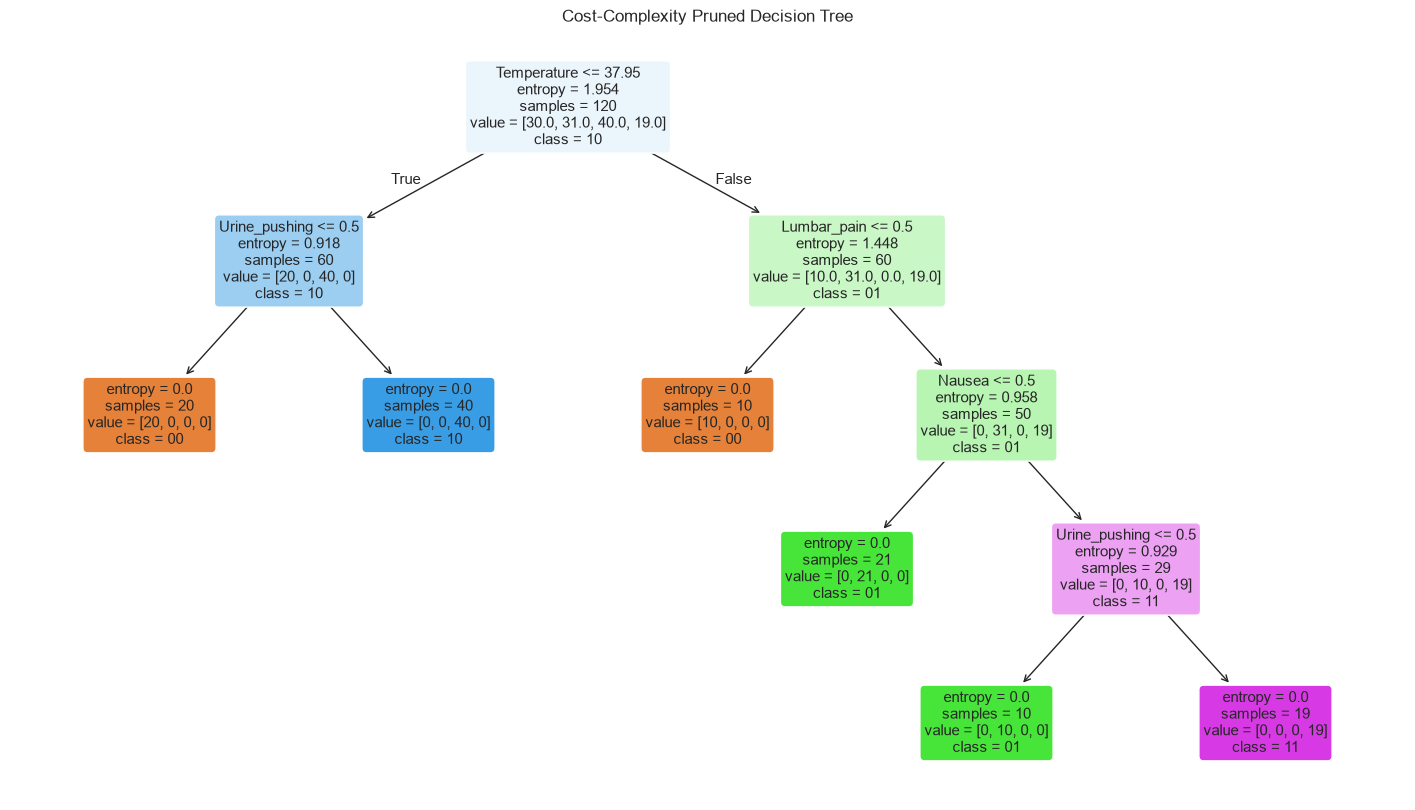


IF-THEN Rules for the Pruned Decision Tree:

Rule 1:
IF Temperature <= 37.95 AND Urine_pushing <= 0.50
THEN disease class = 00

Rule 2:
IF Temperature <= 37.95 AND Urine_pushing > 0.50
THEN disease class = 10

Rule 3:
IF Temperature > 37.95 AND Lumbar_pain <= 0.50
THEN disease class = 00

Rule 4:
IF Temperature > 37.95 AND Lumbar_pain > 0.50 AND Nausea <= 0.50
THEN disease class = 01

Rule 5:
IF Temperature > 37.95 AND Lumbar_pain > 0.50 AND Nausea > 0.50 AND Urine_pushing <= 0.50
THEN disease class = 01

Rule 6:
IF Temperature > 37.95 AND Lumbar_pain > 0.50 AND Nausea > 0.50 AND Urine_pushing > 0.50
THEN disease class = 11

Selected alpha for minimal tree: 0.0
Tree depth: 4
Number of leaves: 6
Training accuracy: 1.0
Best CV accuracy: 1.0


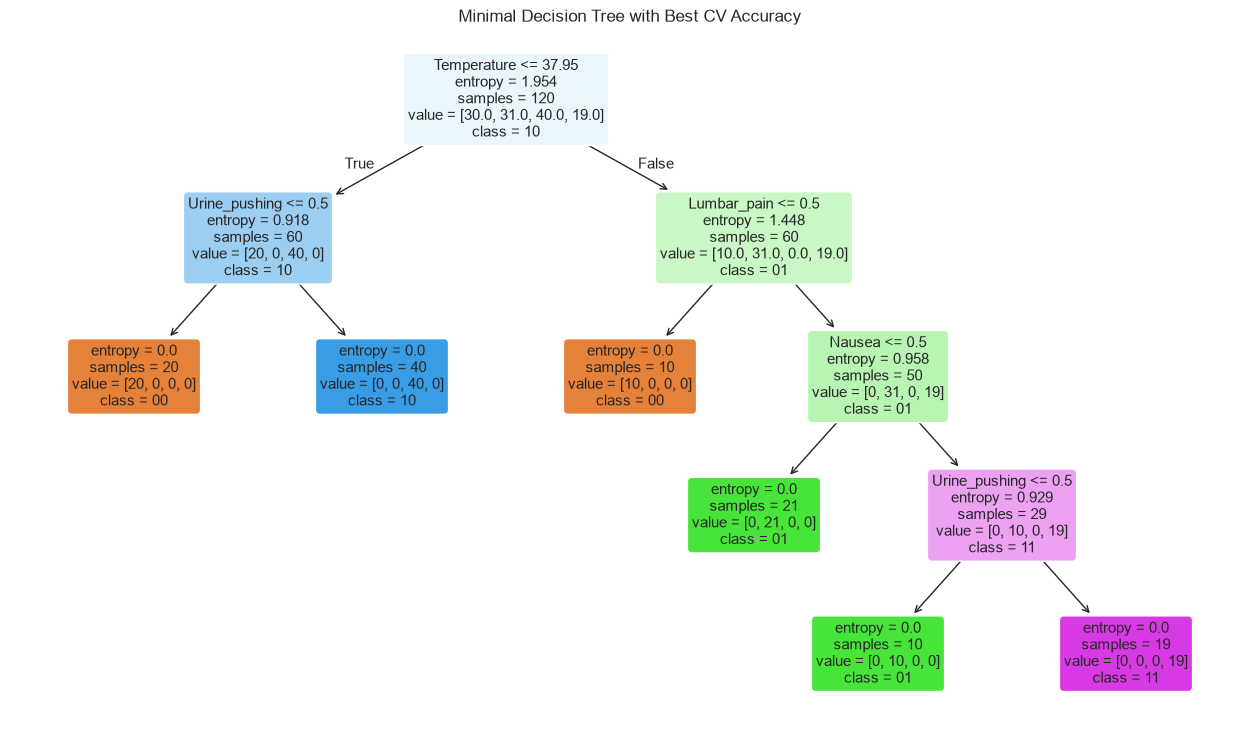


IF-THEN Rules for Minimal Decision Tree:

Rule 1:
IF Temperature <= 37.95 AND Urine_pushing <= 0.50
THEN disease class = 00

Rule 2:
IF Temperature <= 37.95 AND Urine_pushing > 0.50
THEN disease class = 10

Rule 3:
IF Temperature > 37.95 AND Lumbar_pain <= 0.50
THEN disease class = 00

Rule 4:
IF Temperature > 37.95 AND Lumbar_pain > 0.50 AND Nausea <= 0.50
THEN disease class = 01

Rule 5:
IF Temperature > 37.95 AND Lumbar_pain > 0.50 AND Nausea > 0.50 AND Urine_pushing <= 0.50
THEN disease class = 01

Rule 6:
IF Temperature > 37.95 AND Lumbar_pain > 0.50 AND Nausea > 0.50 AND Urine_pushing > 0.50
THEN disease class = 11



In [5]:
# Obtain candidate pruning parameters
path = dt.cost_complexity_pruning_path(X, y_combined)
ccp_alphas = np.unique(path.ccp_alphas)

# Select the pruning parameter using 5-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

param_grid = {"ccp_alpha": ccp_alphas}

grid_search = GridSearchCV(
    DecisionTreeClassifier(criterion="entropy", random_state=42),
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy"
)
grid_search.fit(X, y_combined)

best_alpha = grid_search.best_params_["ccp_alpha"]

# Fit the pruned decision tree on the entire dataset
pruned_dt = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42,
    ccp_alpha=best_alpha
)
pruned_dt.fit(X, y_combined)

print("Optimal ccp_alpha:", best_alpha)
print("Original tree depth:", dt.get_depth())
print("Pruned tree depth:", pruned_dt.get_depth())
print("Original number of leaves:", dt.get_n_leaves())
print("Pruned number of leaves:", pruned_dt.get_n_leaves())
print("Pruned training accuracy:", pruned_dt.score(X, y_combined))
print("Best cross-validation accuracy:", grid_search.best_score_)

# Plot the pruned decision tree
plt.figure(figsize=(18, 10))
plot_tree(
    pruned_dt,
    feature_names=list(X.columns),
    class_names=list(pruned_dt.classes_),
    filled=True,
    rounded=True,
    fontsize=11
)
plt.title("Cost-Complexity Pruned Decision Tree")
plt.show()

# Extract IF-THEN rules from the pruned tree
pruned_rules = extract_rules(pruned_dt, list(X.columns))

print("\nIF-THEN Rules for the Pruned Decision Tree:\n")

for i, (condition, prediction) in enumerate(pruned_rules, start=1):
    print(f"Rule {i}:")
    print(f"IF {condition}")
    print(f"THEN disease class = {prediction}")
    print()


# Find the smallest tree with the best cross-validation accuracy

cv_results = pd.DataFrame(grid_search.cv_results_)

best_cv_score = cv_results["mean_test_score"].max()

# Among models with the best CV accuracy, prefer stronger pruning
eligible = cv_results[
    np.isclose(cv_results["mean_test_score"], best_cv_score)
]

simpler_alpha = eligible["param_ccp_alpha"].astype(float).max()

minimal_dt = DecisionTreeClassifier(
    criterion="entropy",
    ccp_alpha=simpler_alpha,
    random_state=42
)
minimal_dt.fit(X, y_combined)

print("Selected alpha for minimal tree:", simpler_alpha)
print("Tree depth:", minimal_dt.get_depth())
print("Number of leaves:", minimal_dt.get_n_leaves())
print("Training accuracy:", minimal_dt.score(X, y_combined))
print("Best CV accuracy:", best_cv_score)

plt.figure(figsize=(16, 9))
plot_tree(
    minimal_dt,
    feature_names=list(X.columns),
    class_names=list(minimal_dt.classes_),
    filled=True,
    rounded=True,
    fontsize=11
)
plt.title("Minimal Decision Tree with Best CV Accuracy")
plt.show()

print("\nIF-THEN Rules for Minimal Decision Tree:\n")
minimal_rules = extract_rules(minimal_dt, list(X.columns))

for i, (condition, prediction) in enumerate(minimal_rules, 1):
    print(f"Rule {i}:")
    print(f"IF {condition}")
    print(f"THEN disease class = {prediction}\n")

Cost-complexity pruning was performed using 5-fold cross-validation to select the regularization parameter \(\alpha\). The optimal value was \(\alpha=0\), with a cross-validation accuracy of 100%. Consequently, the selected tree remained unchanged, with a maximum depth of 4 and 6 terminal nodes. The final model achieved 100% training accuracy and was represented by six IF–THEN decision rules. These results indicate that, under the selected cross-validation criterion, further pruning did not improve model selection performance. Therefore, the original tree was retained to preserve predictive accuracy and interpretability.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [6]:
import re

# Extract attribute names from the data description
with open("../data/communities.names", "r", encoding="latin-1") as f:
    lines = f.readlines()

feature_names = [
    re.match(r"@attribute\s+(\S+)", line, re.IGNORECASE).group(1)
    for line in lines
    if re.match(r"@attribute\s+(\S+)", line, re.IGNORECASE)
]

# Load the dataset
df_crime = pd.read_csv(
    "../data/communities.data",
    header=None,
    names=feature_names,
    na_values="?"
)

# Split according to the assignment instructions
train_df = df_crime.iloc[:1495].copy()
test_df = df_crime.iloc[1495:].copy()

print("Full dataset shape:", df_crime.shape)
print("Training set shape:", train_df.shape)
print("Test set shape:", test_df.shape)

display(df_crime.head())

Full dataset shape: (1994, 128)
Training set shape: (1495, 128)
Test set shape: (499, 128)


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


### (b) Missing values

In [7]:
non_predictive = [
    "state", "county", "community", "communityname", "fold"
]
target = "ViolentCrimesPerPop"

# Separate predictors and target
X_train_raw = train_df.drop(columns=non_predictive + [target])
X_test_raw = test_df.drop(columns=non_predictive + [target])

y_train = train_df[target].copy()
y_test = test_df[target].copy()

# Convert all predictors to numeric
X_train_raw = X_train_raw.apply(pd.to_numeric, errors="coerce")
X_test_raw = X_test_raw.apply(pd.to_numeric, errors="coerce")

# Inspect missing values before imputation
missing_before = X_train_raw.isna().sum()
print("Missing values in training predictors before imputation:",
      missing_before.sum())

print("Number of features with missing values:",
      (missing_before > 0).sum())

# Remove features that are entirely missing in training
all_missing_cols = X_train_raw.columns[X_train_raw.isna().all()].tolist()

X_train_raw = X_train_raw.drop(columns=all_missing_cols)
X_test_raw = X_test_raw.drop(columns=all_missing_cols)

# Median imputation fitted on training data only
imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train_raw),
    columns=X_train_raw.columns,
    index=X_train_raw.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test_raw),
    columns=X_test_raw.columns,
    index=X_test_raw.index
)

print("\nDropped entirely missing features:", all_missing_cols)
print("Training predictors shape:", X_train.shape)
print("Test predictors shape:", X_test.shape)
print("Missing values after imputation (train):",
      X_train.isna().sum().sum())
print("Missing values after imputation (test):",
      X_test.isna().sum().sum())
print("Missing target values (train/test):",
      y_train.isna().sum(), y_test.isna().sum())

Missing values in training predictors before imputation: 27633
Number of features with missing values: 23

Dropped entirely missing features: []
Training predictors shape: (1495, 122)
Test predictors shape: (499, 122)
Missing values after imputation (train): 0
Missing values after imputation (test): 0
Missing target values (train/test): 0 0


### (c) Plot a correlation matrix

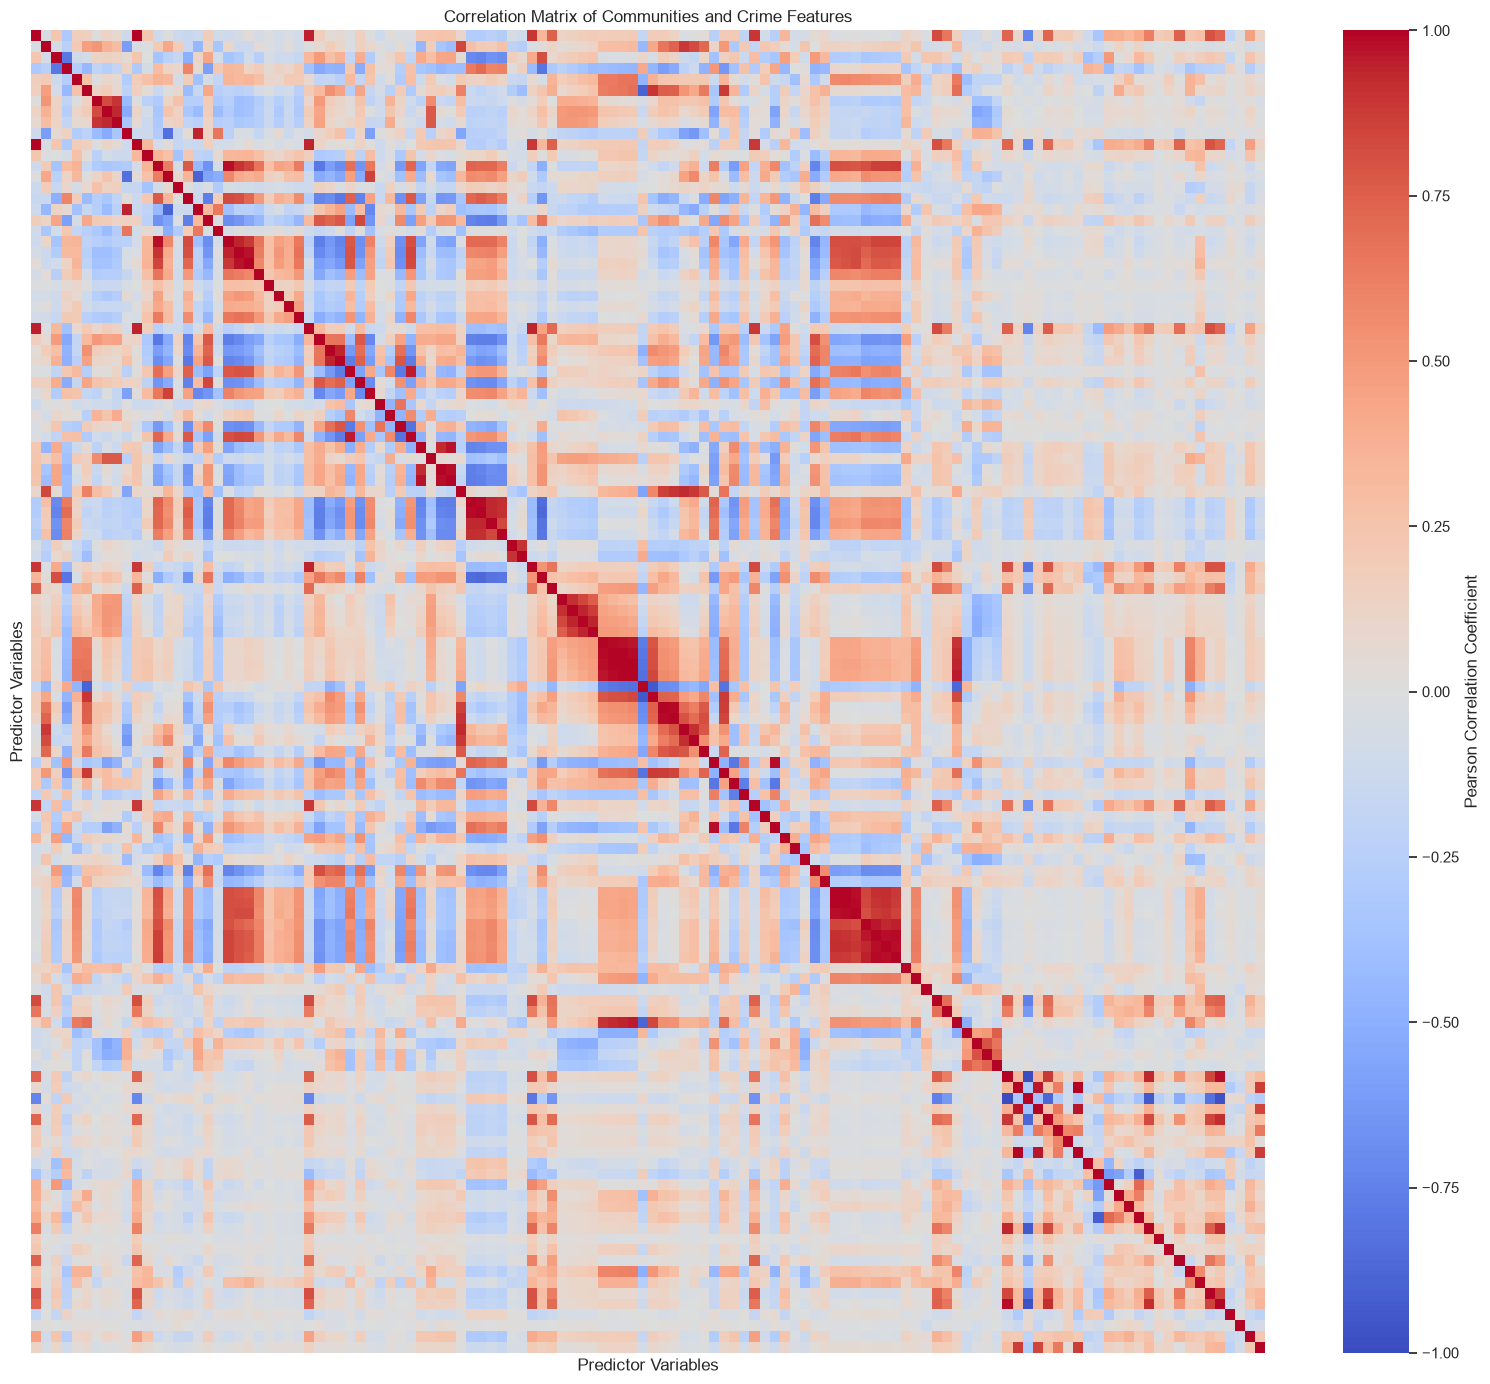

Correlation matrix shape: (122, 122)


In [8]:
# Calculate Pearson correlation matrix using training predictors
corr_matrix = X_train.corr()

# Plot correlation heatmap
plt.figure(figsize=(16, 14))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=False,
    xticklabels=False,
    yticklabels=False,
    cbar_kws={"label": "Pearson Correlation Coefficient"}
)

plt.title("Correlation Matrix of Communities and Crime Features")
plt.xlabel("Predictor Variables")
plt.ylabel("Predictor Variables")
plt.tight_layout()
plt.show()

print("Correlation matrix shape:", corr_matrix.shape)

### (d) Calculate the Coefficient of Variation CV

In [9]:
# Calculate sample mean and sample standard deviation
feature_means = X_train.mean()
feature_stds = X_train.std(ddof=1)

# Calculate coefficient of variation
cv_values = feature_stds / feature_means.replace(0, np.nan)

# Create a summary table
cv_table = pd.DataFrame({
    "Mean": feature_means,
    "Standard Deviation": feature_stds,
    "CV": cv_values
})

# Sort features by CV in descending order
cv_table = cv_table.sort_values(by="CV", ascending=False)

print("Number of features:", len(cv_table))
print("Features with undefined CV:", cv_table["CV"].isna().sum())

display(cv_table)

Number of features: 122
Features with undefined CV: 0


,Mean,Standard Deviation,CV
PctPolicAsian,0.016254,0.089838,5.527059
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
...,...,...,...
NumKindsDrugsSeiz,0.567130,0.079977,0.141021
RacialMatchCommPol,0.722375,0.093657,0.129652
PctPolicWhite,0.762856,0.090572,0.118727
LemasPctPolicOnPatr,0.752495,0.084304,0.112032


### (e) Scatter plots and box plots for highest CV features

Top 11 features with highest CV:


,Mean,Standard Deviation,CV
PctPolicAsian,0.016254,0.089838,5.527059
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
LemasPctOfficDrugUn,0.093304,0.238201,2.552946
NumUnderPov,0.056849,0.133167,2.342443
LemasSwornFT,0.028749,0.064629,2.248042
population,0.058167,0.130359,2.241105
numbUrban,0.064649,0.131784,2.038461


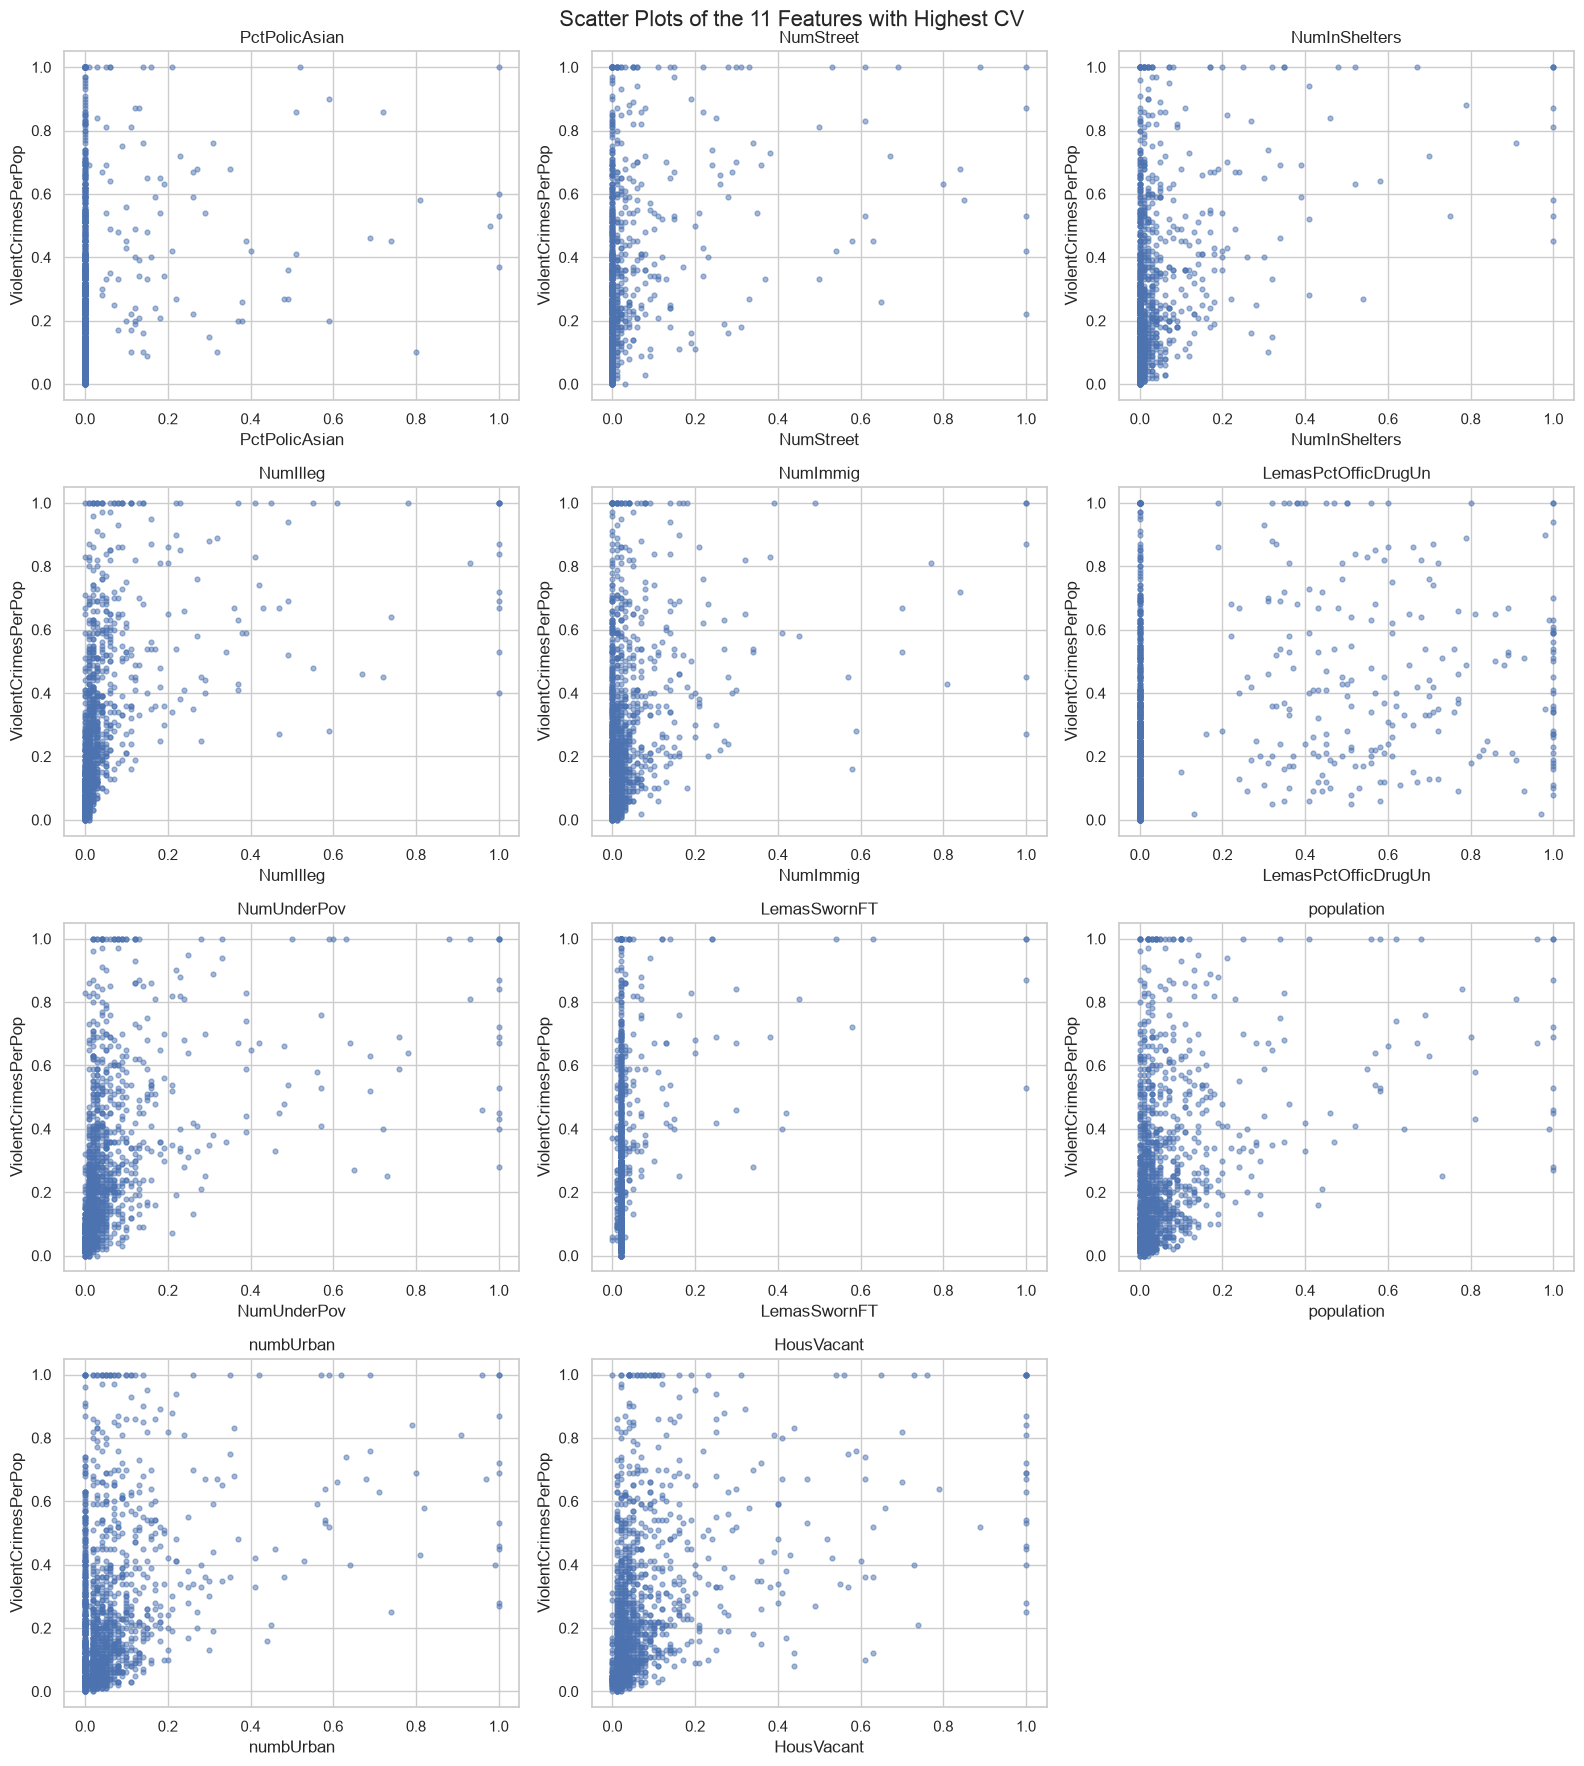

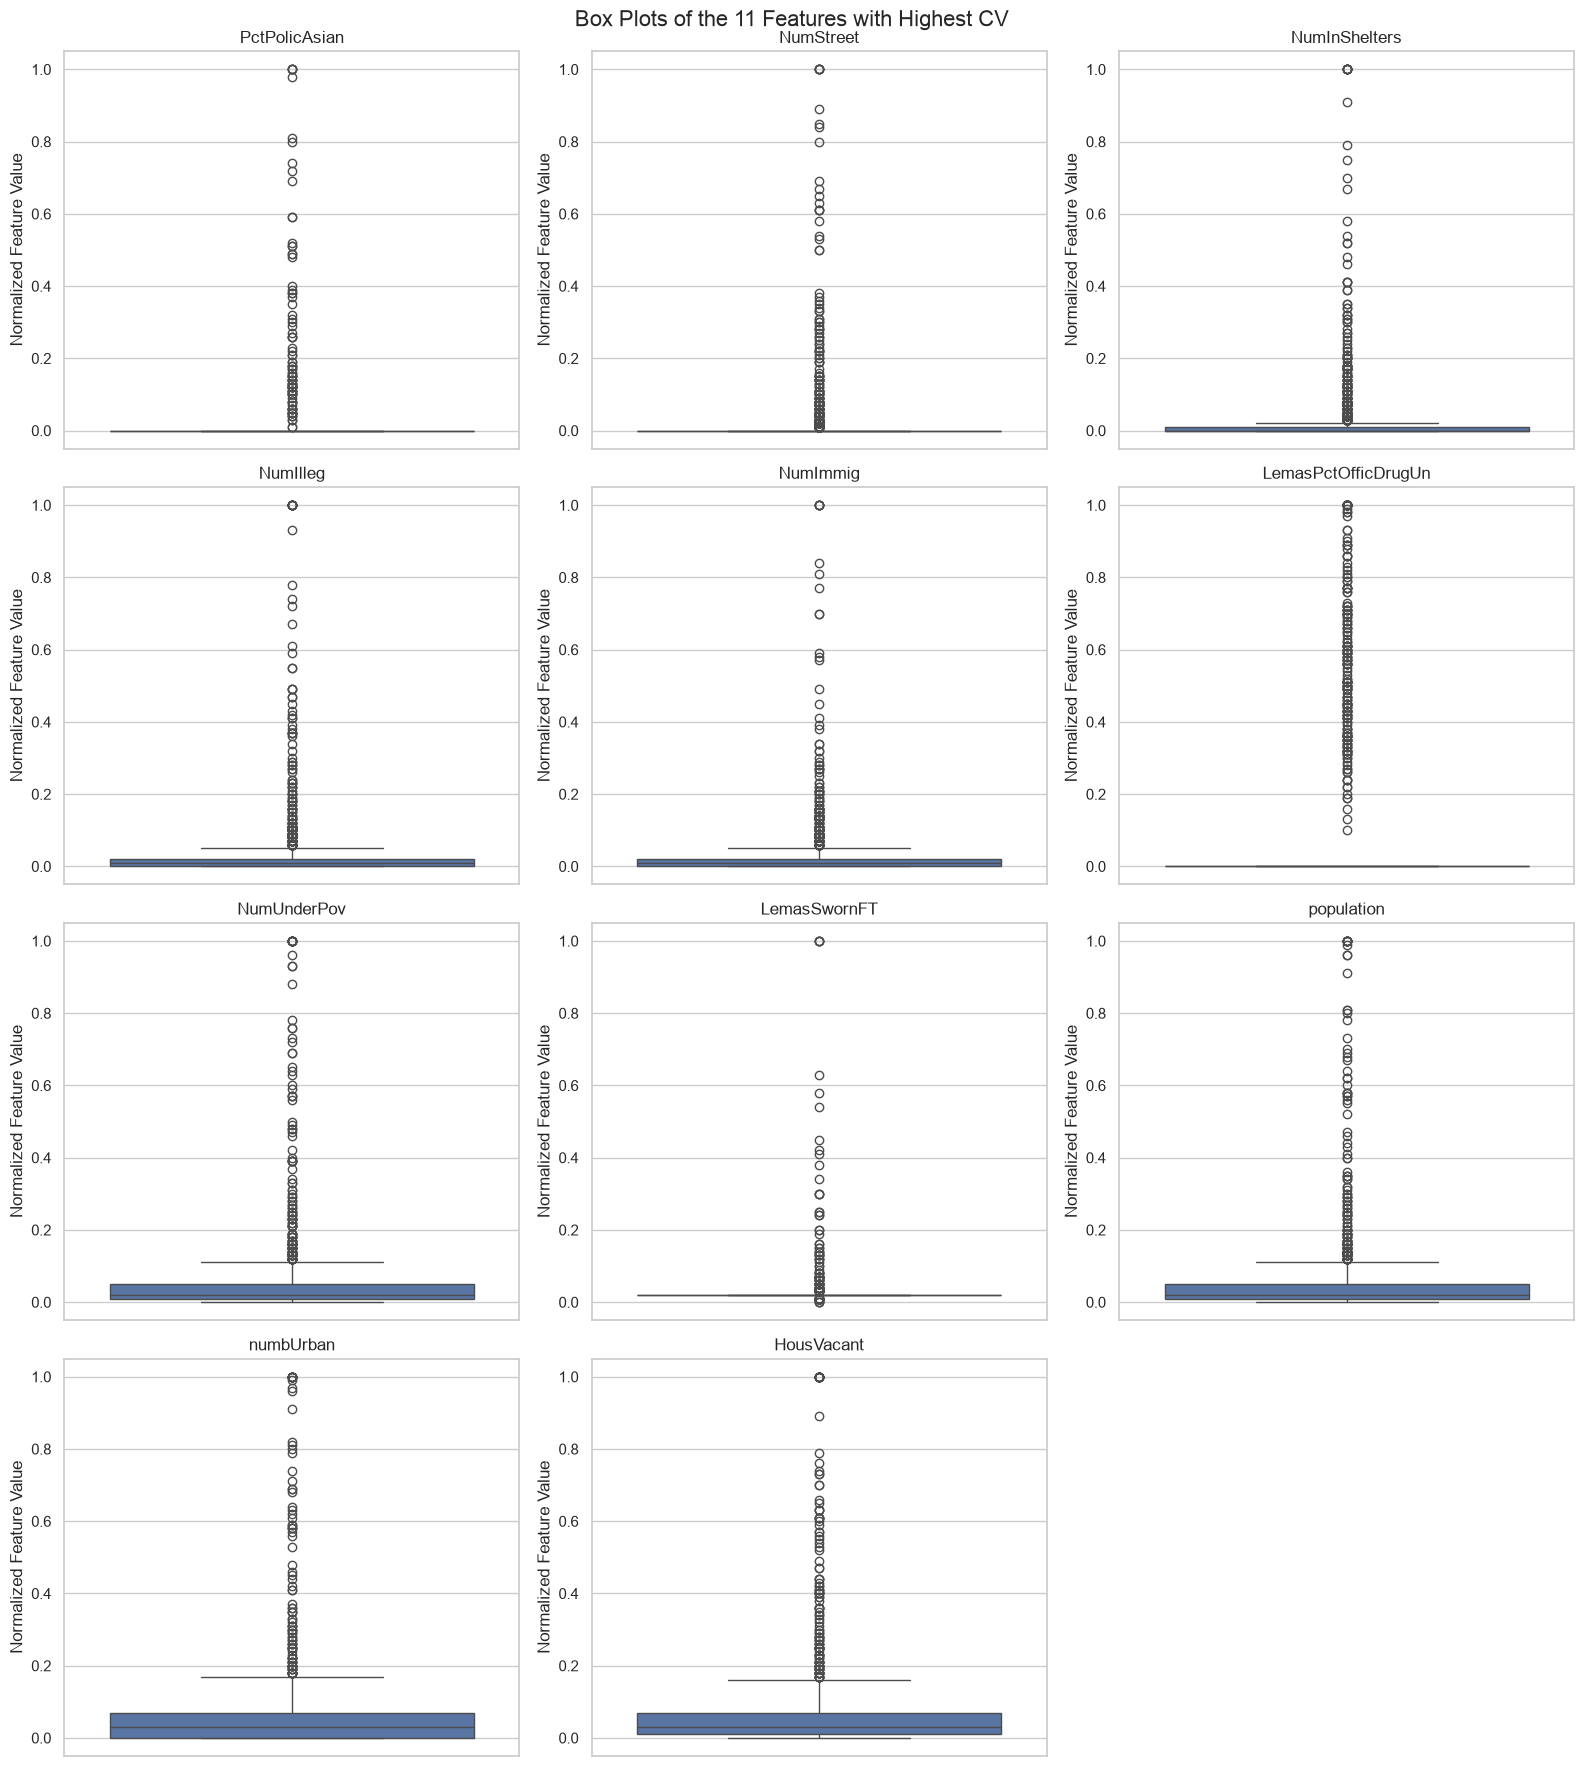

In [10]:
n_features = int(np.floor(np.sqrt(128)))

top_features = cv_table.head(n_features).index.tolist()

print(f"Top {n_features} features with highest CV:")
display(cv_table.loc[top_features])

# Scatter plots against the response variable
fig, axes = plt.subplots(4, 3, figsize=(16, 18))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    axes[i].scatter(
        X_train[feature],
        y_train,
        alpha=0.5,
        s=12
    )
    axes[i].set_title(feature)
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("ViolentCrimesPerPop")

for j in range(len(top_features), len(axes)):
    axes[j].axis("off")

plt.suptitle("Scatter Plots of the 11 Features with Highest CV", fontsize=16)
plt.tight_layout()
plt.show()

# Box plots for the selected features
fig, axes = plt.subplots(4, 3, figsize=(16, 18))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    sns.boxplot(
        y=X_train[feature],
        ax=axes[i]
    )
    axes[i].set_title(feature)
    axes[i].set_ylabel("Normalized Feature Value")

for j in range(len(top_features), len(axes)):
    axes[j].axis("off")

plt.suptitle("Box Plots of the 11 Features with Highest CV", fontsize=16)
plt.tight_layout()
plt.show()

The scatter plots show that most observations are concentrated at relatively low feature values, with considerable dispersion and no consistently strong linear relationships with ViolentCrimesPerPop. The box plots also indicate that many selected features are right-skewed and contain numerous outliers.

However, high coefficients of variation do not necessarily indicate statistical significance or predictive importance. Therefore, the significance of these features cannot be determined from scatter plots alone. Further statistical analysis, such as regression modeling and hypothesis testing, is required.

### (f) Fit a linear model

In [11]:
# Fit ordinary least squares regression
ols_model = LinearRegression()
ols_model.fit(X_train, y_train)

# Predict on training and test datasets
y_train_pred_ols = ols_model.predict(X_train)
y_test_pred_ols = ols_model.predict(X_test)

# Calculate mean squared error
ols_train_mse = mean_squared_error(y_train, y_train_pred_ols)
ols_test_mse = mean_squared_error(y_test, y_test_pred_ols)

print("OLS Training MSE:", round(ols_train_mse, 6))
print("OLS Test MSE:", round(ols_test_mse, 6))

OLS Training MSE: 0.016292
OLS Test MSE: 0.017966


### (g) Fit a ridge regression model

In [12]:
# Candidate regularization parameters
ridge_alphas = np.logspace(-4, 4, 100)

# 5-fold cross-validation
ridge_cv = RidgeCV(
    alphas=ridge_alphas,
    cv=5,
    scoring="neg_mean_squared_error"
)

# Fit Ridge regression on training data
ridge_cv.fit(X_train, y_train)

# Predict on training and test sets
y_train_pred_ridge = ridge_cv.predict(X_train)
y_test_pred_ridge = ridge_cv.predict(X_test)

# Calculate MSE
ridge_train_mse = mean_squared_error(
    y_train, y_train_pred_ridge
)
ridge_test_mse = mean_squared_error(
    y_test, y_test_pred_ridge
)

print("Optimal Ridge lambda:", ridge_cv.alpha_)
print("Ridge Training MSE:", round(ridge_train_mse, 6))
print("Ridge Test MSE:", round(ridge_test_mse, 6))
print("OLS Test MSE:", round(ols_test_mse, 6))

Optimal Ridge lambda: 2.310129700083163
Ridge Training MSE: 0.016977
Ridge Test MSE: 0.017516
OLS Test MSE: 0.017966


### (h) Fit a LASSO model

In [13]:
# LASSO using original features
lasso_original = LassoCV(
    cv=5,
    random_state=42,
    max_iter=100000,
    alphas=100
)

lasso_original.fit(X_train, y_train)

# Calculate test MSE
lasso_original_pred = lasso_original.predict(X_test)
lasso_original_mse = mean_squared_error(
    y_test, lasso_original_pred
)

# Identify selected features
selected_original = X_train.columns[
    np.abs(lasso_original.coef_) > 1e-6
].tolist()

print("=== LASSO: Original Features ===")
print("Optimal alpha:", lasso_original.alpha_)
print("Test MSE:", round(lasso_original_mse, 6))
print("Number of selected features:", len(selected_original))
print("Selected features:")
print(selected_original)


# 2. LASSO using standardized features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lasso_standardized = LassoCV(
    cv=5,
    random_state=42,
    max_iter=100000,
    alphas=100
)

lasso_standardized.fit(X_train_scaled, y_train)

# Calculate test MSE
lasso_standardized_pred = lasso_standardized.predict(
    X_test_scaled
)
lasso_standardized_mse = mean_squared_error(
    y_test, lasso_standardized_pred
)

# Identify selected features
selected_standardized = X_train.columns[
    np.abs(lasso_standardized.coef_) > 1e-6
].tolist()

print("\n=== LASSO: Standardized Features ===")
print("Optimal alpha:", lasso_standardized.alpha_)
print("Test MSE:", round(lasso_standardized_mse, 6))
print("Number of selected features:", len(selected_standardized))
print("Selected features:")
print(selected_standardized)


# 3. Compare the two LASSO models
comparison_lasso = pd.DataFrame({
    "Model": [
        "LASSO (Original)",
        "LASSO (Standardized)"
    ],
    "Optimal Alpha": [
        lasso_original.alpha_,
        lasso_standardized.alpha_
    ],
    "Test MSE": [
        lasso_original_mse,
        lasso_standardized_mse
    ],
    "Number of Selected Features": [
        len(selected_original),
        len(selected_standardized)
    ]
})

print("\n=== LASSO Comparison ===")
display(comparison_lasso)

# Identify the model with lower test error
if lasso_original_mse < lasso_standardized_mse:
    print("The LASSO model using original features has lower test MSE.")
elif lasso_original_mse > lasso_standardized_mse:
    print("The standardized LASSO model has lower test MSE.")
else:
    print("Both LASSO models have the same test MSE.")

=== LASSO: Original Features ===
Optimal alpha: 0.0001245408743775853
Test MSE: 0.017618
Number of selected features: 74
Selected features:
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnC

,Model,Optimal Alpha,Test MSE,Number of Selected Features
0,LASSO (Original),0.000125,0.017618,74
1,LASSO (Standardized),0.000763,0.017682,72


The LASSO model using original features has lower test MSE.


The LASSO model using the original features achieved a test MSE of 0.017618 and selected 74 predictors, whereas the standardized LASSO model achieved a test MSE of 0.017682 and selected 72 predictors. Standardization resulted in a slightly sparser model but did not improve test-set predictive accuracy. Overall, the two models performed similarly, with the original-feature LASSO achieving a marginally lower test MSE.

### (i) Fit a PCR model

Optimal number of principal components (M): 60
PCR Training MSE: 0.017939
PCR Test MSE: 0.01835
Best CV MSE: 0.020215


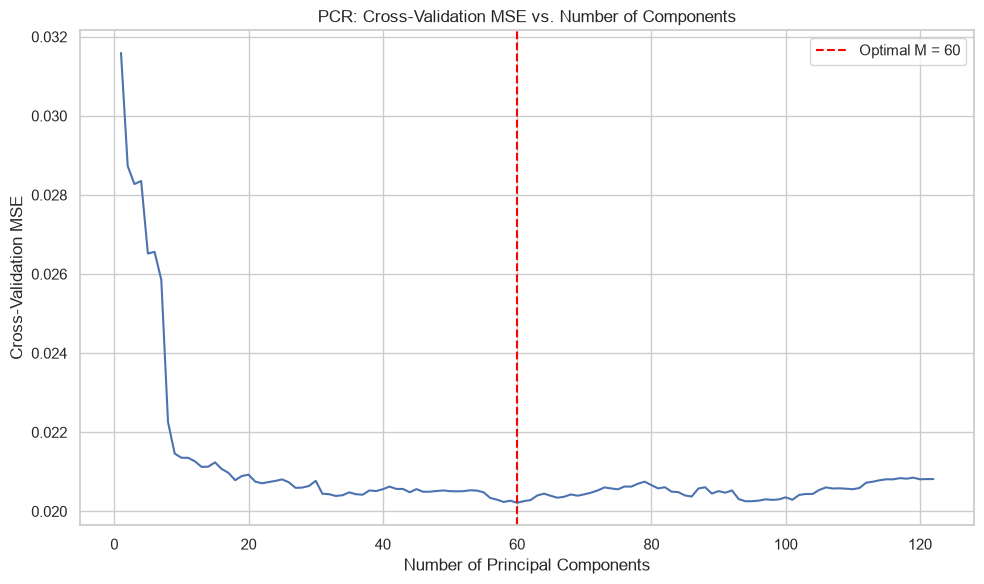

In [14]:
# Construct a pipeline for scaling, PCA, and linear regression
pcr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("regression", LinearRegression())
])

# Candidate numbers of principal components
n_components = list(range(1, X_train.shape[1] + 1))

# 5-fold cross-validation to select M
pcr_grid = GridSearchCV(
    estimator=pcr_pipeline,
    param_grid={"pca__n_components": n_components},
    scoring="neg_mean_squared_error",
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1
)

pcr_grid.fit(X_train, y_train)

# Best number of principal components
best_M = pcr_grid.best_params_["pca__n_components"]
best_pcr = pcr_grid.best_estimator_

# Predictions
y_train_pred_pcr = best_pcr.predict(X_train)
y_test_pred_pcr = best_pcr.predict(X_test)

# Calculate MSE
pcr_train_mse = mean_squared_error(y_train, y_train_pred_pcr)
pcr_test_mse = mean_squared_error(y_test, y_test_pred_pcr)

print("Optimal number of principal components (M):", best_M)
print("PCR Training MSE:", round(pcr_train_mse, 6))
print("PCR Test MSE:", round(pcr_test_mse, 6))
print("Best CV MSE:", round(-pcr_grid.best_score_, 6))

# Plot cross-validation error against number of components
cv_mse = -pcr_grid.cv_results_["mean_test_score"]

plt.figure(figsize=(10, 6))
plt.plot(n_components, cv_mse)
plt.axvline(best_M, color="red", linestyle="--",
            label=f"Optimal M = {best_M}")

plt.xlabel("Number of Principal Components")
plt.ylabel("Cross-Validation MSE")
plt.title("PCR: Cross-Validation MSE vs. Number of Components")
plt.legend()
plt.tight_layout()
plt.show()

### (j) Fit a boosting tree

In [15]:
# Candidate L1 regularization parameters
alpha_grid = [0, 0.001, 0.01, 0.1, 0.5, 1, 2, 5, 10]

# Initialize XGBoost regressor
xgb_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=1.0,
    colsample_bytree=1.0,
    reg_lambda=0,
    random_state=42,
    n_jobs=1
)

# Tune L1 regularization using 5-fold cross-validation
xgb_grid = GridSearchCV(
    estimator=xgb_model,
    param_grid={"reg_alpha": alpha_grid},
    scoring="neg_mean_squared_error",
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1
)

xgb_grid.fit(X_train, y_train)

# Best model and regularization parameter
best_xgb = xgb_grid.best_estimator_
best_alpha_xgb = xgb_grid.best_params_["reg_alpha"]

# Predictions
y_train_pred_xgb = best_xgb.predict(X_train)
y_test_pred_xgb = best_xgb.predict(X_test)

# Calculate MSE
xgb_train_mse = mean_squared_error(
    y_train, y_train_pred_xgb
)
xgb_test_mse = mean_squared_error(
    y_test, y_test_pred_xgb
)

print("=== XGBoost with L1 Regularization ===")
print("Optimal alpha:", best_alpha_xgb)
print("Training MSE:", round(xgb_train_mse, 6))
print("Test MSE:", round(xgb_test_mse, 6))
print("Best CV MSE:", round(-xgb_grid.best_score_, 6))

# Compare all regression models
model_comparison = pd.DataFrame({
    "Model": [
        "OLS",
        "Ridge",
        "LASSO (Original)",
        "LASSO (Standardized)",
        "PCR",
        "XGBoost (L1)"
    ],
    "Test MSE": [
        ols_test_mse,
        ridge_test_mse,
        lasso_original_mse,
        lasso_standardized_mse,
        pcr_test_mse,
        xgb_test_mse
    ]
})

model_comparison = model_comparison.sort_values(
    by="Test MSE"
).reset_index(drop=True)

print("\n=== Final Model Comparison ===")
display(model_comparison)

print("Model with lowest test MSE:",
      model_comparison.loc[0, "Model"])

=== XGBoost with L1 Regularization ===
Optimal alpha: 1
Training MSE: 0.007663
Test MSE: 0.016703
Best CV MSE: 0.020065

=== Final Model Comparison ===


,Model,Test MSE
0,XGBoost (L1),0.016703
1,Ridge,0.017516
2,LASSO (Original),0.017618
3,LASSO (Standardized),0.017682
4,OLS,0.017966
5,PCR,0.018350


Model with lowest test MSE: XGBoost (L1)
